# Analyse exploratoire des données

Cette analyse exploratoire a pour objectif de décrire les principales caractéristiques
du jeu de données Pokémon nettoyé, d'identifier des relations entre les variables et
de formuler des hypothèses qui pourront être étudiées à l'aide de méthodes statistiques
et factorielles.

Les analyses sont réalisées sur le jeu de données `pokemons_analysis.csv`, dans lequel
les profils analytiques strictement redondants ont été retirés afin d'éviter de
surpondérer artificiellement certains Pokémon.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

Matplotlib is building the font cache; this may take a moment.


## 1. Présentation du jeu de données

L'analyse exploratoire est réalisée sur le jeu de données préparé spécifiquement pour
les analyses statistiques. Les profils strictement redondants ont été retirés afin
d'éviter de surpondérer artificiellement certains Pokémon ou certaines formes.

Cette première étape consiste à vérifier la structure générale du jeu de données avant
d'étudier séparément les variables quantitatives et qualitatives.

In [3]:
df = pd.read_csv("../data/processed/pokemons_analysis.csv")

print("Nombre d'observations :", len(df))
print("Nombre de variables :", len(df.columns))
print("Nombre de numéros de Pokédex distincts :", df["Numero"].nunique())
print("Nombre de noms distincts :", df["Nom"].nunique())

Nombre d'observations : 1100
Nombre de variables : 23
Nombre de numéros de Pokédex distincts : 904
Nombre de noms distincts : 1100


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 23 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Numero           1100 non-null   int64  
 1   Nom              1100 non-null   object 
 2   Generation       1100 non-null   int64  
 3   Type1            1100 non-null   object 
 4   Type2            1100 non-null   object 
 5   Taille_m         1096 non-null   float64
 6   Poids_kg         1064 non-null   float64
 7   TauxCapture      1016 non-null   float64
 8   Experience       1100 non-null   float64
 9   PokemonDepart    1100 non-null   bool   
 10  Base             1100 non-null   bool   
 11  Evolution        1100 non-null   bool   
 12  MegaEvolution    1100 non-null   bool   
 13  Gigamax          1100 non-null   bool   
 14  Legendaire       1100 non-null   bool   
 15  PV               1100 non-null   float64
 16  Attaque          1100 non-null   float64
 17  Defense       

## 2. Analyse descriptive des variables quantitatives

Les principales variables quantitatives sont étudiées afin de caractériser leur
distribution, leur dispersion et leurs valeurs extrêmes.

Les variables `Numero` et `Generation` ne sont pas considérées comme des mesures
quantitatives continues : elles servent principalement à identifier ou catégoriser
les Pokémon.

La variable `Total` est conservée pour la description générale, mais elle ne sera pas
utilisée simultanément avec les six statistiques de combat dans les analyses factorielles,
car elle correspond exactement à leur somme.

In [5]:
variables_quanti = [
    "Taille_m",
    "Poids_kg",
    "TauxCapture",
    "Experience",
    "PV",
    "Attaque",
    "Defense",
    "AttaqueSpeciale",
    "DefenseSpeciale",
    "Vitesse",
    "Total"
]

description_quanti = df[variables_quanti].describe().T

description_quanti

,count,mean,std,min,25%,50%,75%,max
Taille_m,1096.0,2.127920e+00,5.729828,0.1,0.600,1.0,1.600,100.0
Poids_kg,1064.0,7.388496e+01,135.331453,0.1,9.475,30.0,75.525,999.9
TauxCapture,1016.0,9.402461e+01,76.452080,3.0,45.000,60.0,130.000,255.0
Experience,1100.0,1.062312e+06,155830.349660,600000.0,1000000.000,1029930.0,1250000.000,1640000.0
PV,1100.0,7.078545e+01,26.807156,1.0,52.000,69.0,85.000,255.0
Attaque,1100.0,8.142545e+01,32.423479,5.0,57.750,80.0,100.000,190.0
Defense,1100.0,7.524000e+01,31.148455,5.0,52.000,70.0,92.500,250.0
AttaqueSpeciale,1100.0,7.340909e+01,32.831911,10.0,50.000,65.0,95.000,194.0
DefenseSpeciale,1100.0,7.256818e+01,27.874767,20.0,50.000,70.0,90.000,250.0
Vitesse,1100.0,6.913273e+01,30.132353,5.0,45.000,66.0,90.000,200.0


In [6]:
description_quanti["mediane"] = df[variables_quanti].median()
description_quanti["manquants"] = df[variables_quanti].isna().sum()

description_quanti[
    [
        "count",
        "manquants",
        "mean",
        "mediane",
        "std",
        "min",
        "25%",
        "75%",
        "max"
    ]
]

,count,manquants,mean,mediane,std,min,25%,75%,max
Taille_m,1096.0,4,2.127920e+00,1.0,5.729828,0.1,0.600,1.600,100.0
Poids_kg,1064.0,36,7.388496e+01,30.0,135.331453,0.1,9.475,75.525,999.9
TauxCapture,1016.0,84,9.402461e+01,60.0,76.452080,3.0,45.000,130.000,255.0
Experience,1100.0,0,1.062312e+06,1029930.0,155830.349660,600000.0,1000000.000,1250000.000,1640000.0
PV,1100.0,0,7.078545e+01,69.0,26.807156,1.0,52.000,85.000,255.0
Attaque,1100.0,0,8.142545e+01,80.0,32.423479,5.0,57.750,100.000,190.0
Defense,1100.0,0,7.524000e+01,70.0,31.148455,5.0,52.000,92.500,250.0
AttaqueSpeciale,1100.0,0,7.340909e+01,65.0,32.831911,10.0,50.000,95.000,194.0
DefenseSpeciale,1100.0,0,7.256818e+01,70.0,27.874767,20.0,50.000,90.000,250.0
Vitesse,1100.0,0,6.913273e+01,66.0,30.132353,5.0,45.000,90.000,200.0


### 2.1 Valeurs extrêmes

Les statistiques descriptives mettent en évidence plusieurs valeurs très éloignées
du centre des distributions, notamment pour la taille, le poids et le total des
statistiques de combat.

Ces observations sont identifiées afin de déterminer si elles correspondent à des
Pokémon particuliers cohérents ou à d'éventuelles anomalies résiduelles.

In [7]:
variables_extremes = [
    "Taille_m",
    "Poids_kg",
    "TauxCapture",
    "PV",
    "Attaque",
    "Defense",
    "AttaqueSpeciale",
    "DefenseSpeciale",
    "Vitesse",
    "Total"
]

for var in variables_extremes:
    print(f"\n=== {var} : valeurs maximales ===")
    display(
        df.nlargest(5, var)[
            ["Numero", "Nom", var, "Legendaire", "MegaEvolution", "Gigamax"]
        ]
    )

    print(f"=== {var} : valeurs minimales ===")
    display(
        df.nsmallest(5, var)[
            ["Numero", "Nom", var, "Legendaire", "MegaEvolution", "Gigamax"]
        ]
    )


=== Taille_m : valeurs maximales ===


,Numero,Nom,Taille_m,Legendaire,MegaEvolution,Gigamax
1078,890,Éthernatos Infinimax,100.0,True,False,False
1030,851,Scolocendre Gigamax,75.0,False,False,True
1069,884,Duralugon Gigamax,43.0,False,False,True
1013,839,Monthracite Gigamax,42.0,False,False,True
988,818,Lézargus Gigamax,40.0,False,False,True


=== Taille_m : valeurs minimales ===


,Numero,Nom,Taille_m,Legendaire,MegaEvolution,Gigamax
729,595,Statitik,0.1,False,False,False
812,669,Flabébé,0.1,False,False,False
903,742,Bombydou,0.1,False,False,False
928,764,Guérilande,0.1,False,False,False
953,790,Cosmovum,0.1,True,False,False



=== Poids_kg : valeurs maximales ===


...

,Numero,Nom,Vitesse,Legendaire,MegaEvolution,Gigamax
285,213,Caratroc,5.0,False,False,False
557,446,Goinfrex,5.0,False,False,False
935,771,Concombaffe,5.0,False,False,False
418,328,Kraknoix,10.0,False,False,False
548,438,Manzaï,10.0,False,False,False



=== Total : valeurs maximales ===


,Numero,Nom,Total,Legendaire,MegaEvolution,Gigamax
1078,890,Éthernatos Infinimax,1125.0,True,False,False
214,150,Méga-Mewtwo X,780.0,True,True,False
215,150,Méga-Mewtwo Y,780.0,True,True,False
488,384,Méga-Rayquaza,780.0,True,True,False
484,382,Primo-Kyogre,770.0,True,False,False


=== Total : valeurs minimales ===


,Numero,Nom,Total,Legendaire,MegaEvolution,Gigamax
909,746,Froussardine - Forme Solitaire,175.0,False,False,False
258,191,Tournegrin,180.0,False,False,False
995,824,Larvadar,180.0,False,False,False
1054,872,Frissonille,185.0,False,False,False
381,298,Azurill,190.0,False,False,False


### 2.2 Distribution des principales variables quantitatives

Les distributions de la taille, du poids, du taux de capture et du total des statistiques
sont étudiées afin d'identifier leur forme, leur asymétrie et la présence éventuelle
de valeurs extrêmes.

Ces graphiques permettent de compléter les statistiques descriptives et de préparer
les hypothèses qui seront testées dans la suite de l'analyse.

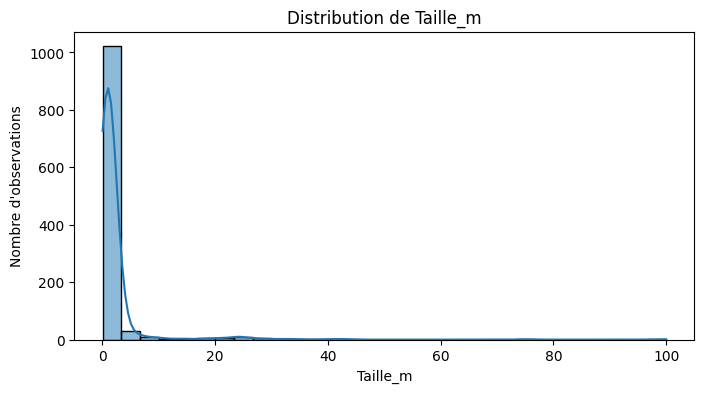

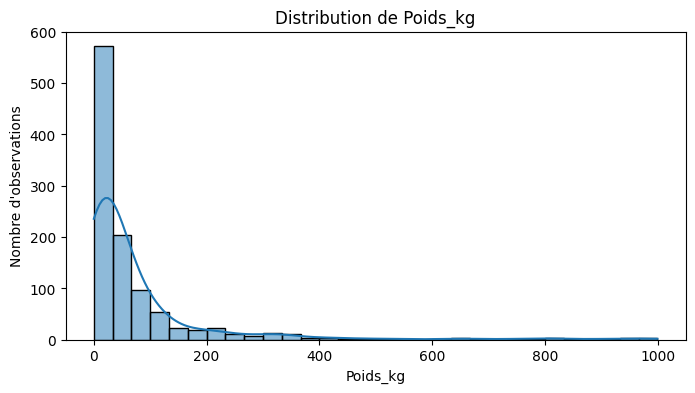

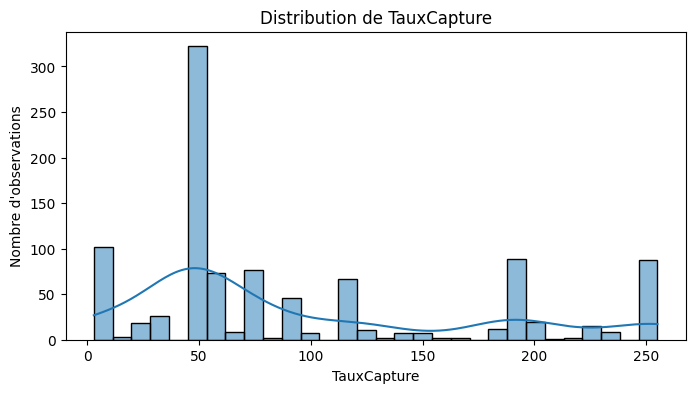

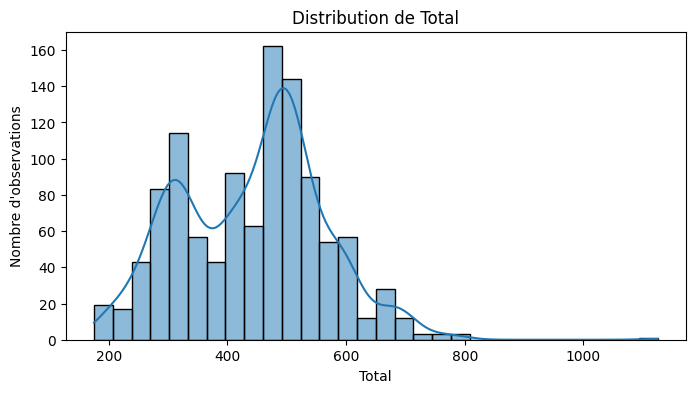

In [8]:
variables_distribution = [
    "Taille_m",
    "Poids_kg",
    "TauxCapture",
    "Total"
]

for var in variables_distribution:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=var,
        bins=30,
        kde=True
    )

    plt.title(f"Distribution de {var}")
    plt.xlabel(var)
    plt.ylabel("Nombre d'observations")

    plt.show()

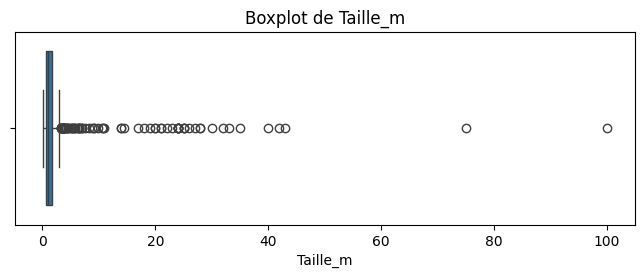

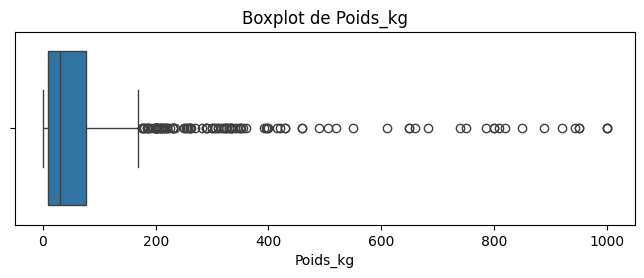

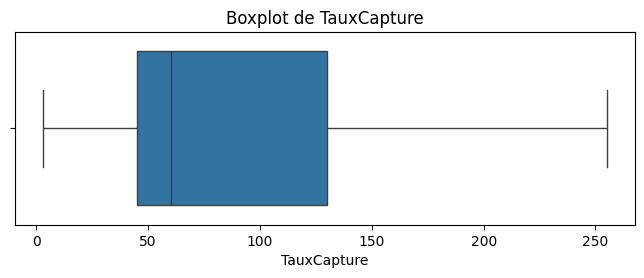

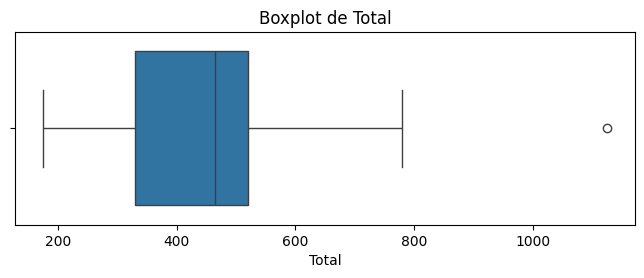

In [9]:
for var in variables_distribution:
    plt.figure(figsize=(8, 2.5))

    sns.boxplot(
        data=df,
        x=var
    )

    plt.title(f"Boxplot de {var}")
    plt.xlabel(var)

    plt.show()

### Interprétation des distributions

Les distributions de `Taille_m` et `Poids_kg` sont fortement asymétriques à droite.
La majorité des Pokémon présentent des valeurs relativement faibles, tandis qu'un petit
nombre de formes très grandes ou très lourdes créent une longue traîne et de nombreux
points extrêmes dans les boxplots.

Le `TauxCapture` présente une distribution discrète et irrégulière, avec plusieurs pics
correspondant à des valeurs de capture fréquemment utilisées dans le jeu. Contrairement
à la taille et au poids, le boxplot ne met pas en évidence d'observation isolée extrême.

La variable `Total` présente plusieurs zones de concentration et un point particulièrement
atypique : Éthernatos Infinimax, dont le total de statistiques atteint 1125, très au-dessus
des autres observations.

Ces distributions montrent que certaines variables sont fortement influencées par des
valeurs extrêmes. Cette caractéristique devra être prise en compte dans les analyses
de corrélation et les méthodes factorielles.

## 3. Corrélations entre variables quantitatives

Les relations entre variables quantitatives sont étudiées à l'aide des coefficients
de corrélation de Pearson et de Spearman.

Le coefficient de Pearson mesure principalement les relations linéaires, tandis que
le coefficient de Spearman repose sur les rangs et est moins sensible aux distributions
asymétriques et aux valeurs extrêmes.

Les deux approches sont comparées notamment pour les variables `Taille_m`, `Poids_kg`
et `TauxCapture`.

In [10]:
variables_correlation = [
    "Taille_m",
    "Poids_kg",
    "TauxCapture",
    "Experience",
    "PV",
    "Attaque",
    "Defense",
    "AttaqueSpeciale",
    "DefenseSpeciale",
    "Vitesse"
]

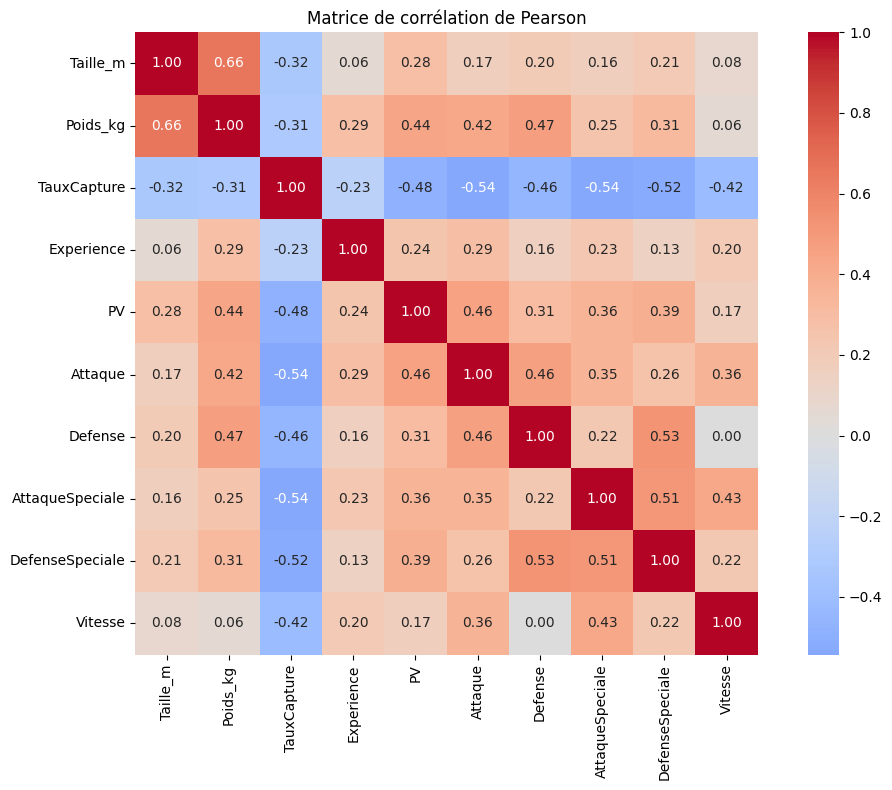

In [11]:
corr_pearson = df[variables_correlation].corr(method="pearson")

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Matrice de corrélation de Pearson")
plt.tight_layout()
plt.show()

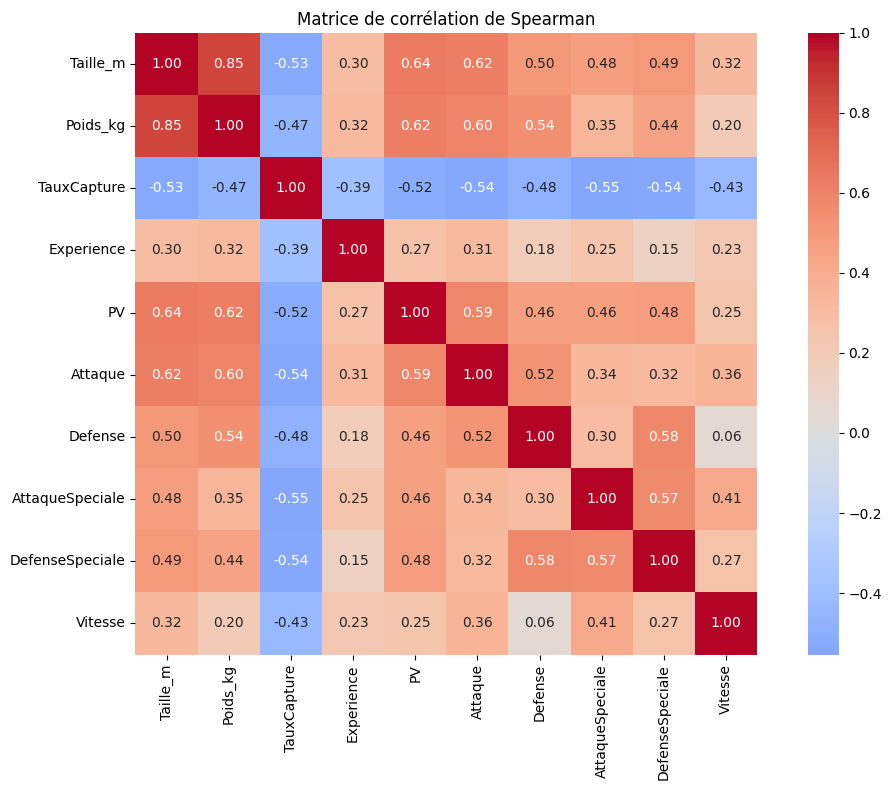

In [12]:
corr_spearman = df[variables_correlation].corr(method="spearman")

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Matrice de corrélation de Spearman")
plt.tight_layout()
plt.show()

In [13]:
correlations = []

for i in range(len(variables_correlation)):
    for j in range(i + 1, len(variables_correlation)):
        var1 = variables_correlation[i]
        var2 = variables_correlation[j]

        correlations.append({
            "Variable 1": var1,
            "Variable 2": var2,
            "Spearman": corr_spearman.loc[var1, var2]
        })

correlations = pd.DataFrame(correlations)

correlations["abs_corr"] = correlations["Spearman"].abs()

correlations.sort_values(
    "abs_corr",
    ascending=False
).head(15)[
    ["Variable 1", "Variable 2", "Spearman"]
]

,Variable 1,Variable 2,Spearman
0,Taille_m,Poids_kg,0.846165
3,Taille_m,PV,0.640704
11,Poids_kg,PV,0.619065
4,Taille_m,Attaque,0.618933
12,Poids_kg,Attaque,0.599068
30,PV,Attaque,0.589148
40,Defense,DefenseSpeciale,0.582912
42,AttaqueSpeciale,DefenseSpeciale,0.572606
21,TauxCapture,AttaqueSpeciale,-0.553670
13,Poids_kg,Defense,0.540305


### Interprétation des corrélations

Les coefficients de Spearman sont globalement plus élevés que ceux de Pearson pour
certaines variables physiques, ce qui confirme que plusieurs relations sont monotones
sans être parfaitement linéaires et qu'elles sont influencées par des valeurs extrêmes.

La relation la plus forte concerne la taille et le poids (`rho ≈ 0,85`) : les Pokémon
les plus grands tendent généralement à être plus lourds.

La taille et le poids sont également positivement associés aux PV et à l'Attaque,
ce qui suggère que les Pokémon physiquement imposants ont tendance à présenter des
profils de combat plus robustes ou plus offensifs.

Le taux de capture présente des corrélations négatives modérées avec la plupart des
statistiques de combat. Les Pokémon possédant des statistiques élevées tendent donc
à avoir un taux de capture plus faible.

Enfin, contrairement à une intuition possible, le poids n'est pas négativement associé
à la Vitesse. Cette relation pourra être étudiée plus finement dans la suite de l'analyse.

Ces résultats décrivent des associations et ne permettent pas d'établir de relation causale.

### 3.1 Hypothèses statistiques

Le seuil de significativité est fixé à `α = 5 %`.

Les relations suivantes sont étudiées à l'aide du coefficient de corrélation de Spearman :

- H1 : la taille et le poids sont positivement associés ;
- H2 : le taux de capture est négativement associé à la puissance globale du Pokémon ;
- H3 : la taille est positivement associée aux PV ;
- H4 : le poids est associé à la Vitesse.

Le test de Spearman est privilégié en raison de l'asymétrie de plusieurs distributions
et de la présence de valeurs extrêmes.

In [14]:
tests_spearman = [
    ("Taille_m", "Poids_kg"),
    ("TauxCapture", "Total"),
    ("Taille_m", "PV"),
    ("Poids_kg", "Vitesse")
]

resultats_tests = []

for var1, var2 in tests_spearman:
    temp = df[[var1, var2]].dropna()

    rho, p_value = stats.spearmanr(
        temp[var1],
        temp[var2]
    )

    resultats_tests.append({
        "Variable 1": var1,
        "Variable 2": var2,
        "n": len(temp),
        "rho": rho,
        "p_value": p_value
    })

pd.DataFrame(resultats_tests)

,Variable 1,Variable 2,n,rho,p_value
0,Taille_m,Poids_kg,1064,0.846165,1.503885e-292
1,TauxCapture,Total,1016,-0.746799,7.932427e-182
2,Taille_m,PV,1096,0.640704,1.069369e-127
3,Poids_kg,Vitesse,1064,0.199855,4.771824e-11


### Interprétation des tests de Spearman

Au seuil de significativité de 5 %, les quatre relations testées sont statistiquement
significatives (`p < 0,05`).

- **Taille et poids** : `rho = 0,846`, `p < 0,001`.
  La relation est positive et très forte : les Pokémon les plus grands tendent
  fortement à être les plus lourds.

- **Taux de capture et Total** : `rho = -0,747`, `p < 0,001`.
  La relation est négative et forte : les Pokémon ayant des statistiques globales
  élevées tendent à présenter un taux de capture plus faible.

- **Taille et PV** : `rho = 0,641`, `p < 0,001`.
  Une association positive importante est observée : les Pokémon de grande taille
  tendent à posséder davantage de PV.

- **Poids et Vitesse** : `rho = 0,200`, `p < 0,001`.
  La relation est statistiquement significative mais faible. Contrairement à
  l'intuition selon laquelle les Pokémon lourds seraient nécessairement plus lents,
  aucune association négative n'est observée.

La significativité statistique ne doit pas être confondue avec la force de la relation :
le lien entre poids et vitesse est significatif en raison notamment de la taille
importante de l'échantillon, mais son intensité reste faible.

Ces résultats décrivent des associations monotones et ne permettent pas de conclure
à des relations causales.

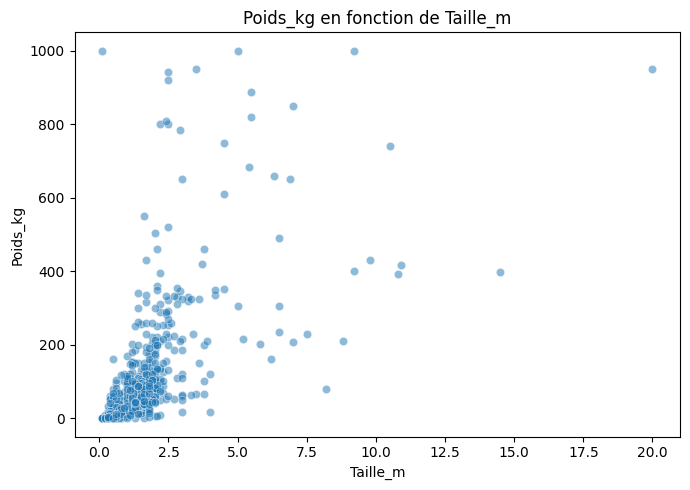

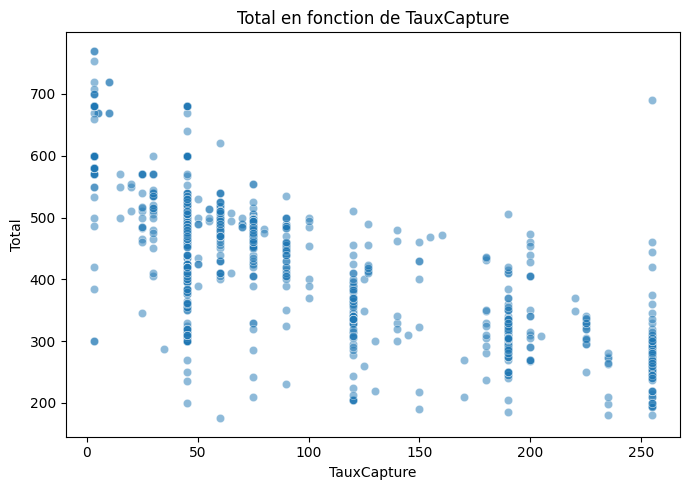

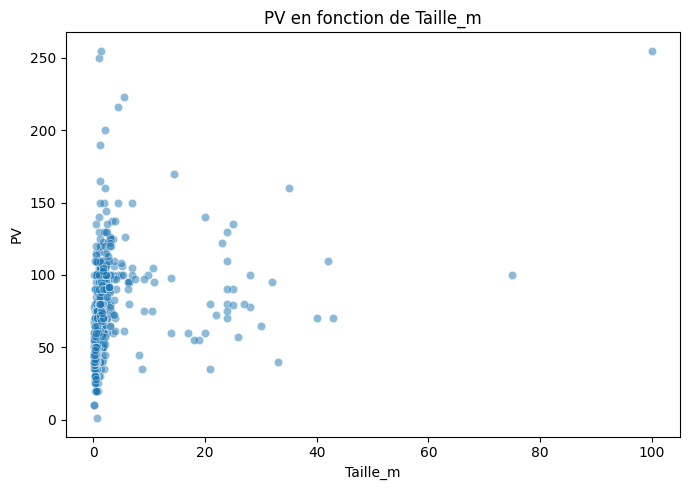

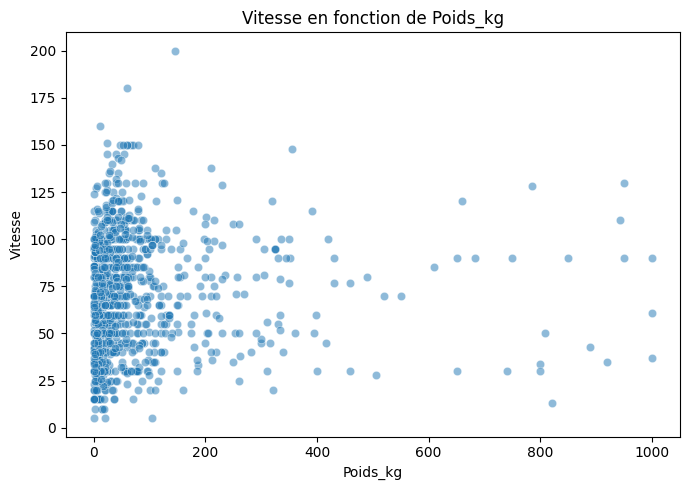

In [15]:
relations = [
    ("Taille_m", "Poids_kg"),
    ("TauxCapture", "Total"),
    ("Taille_m", "PV"),
    ("Poids_kg", "Vitesse")
]

for x, y in relations:
    temp = df[[x, y]].dropna()

    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=temp,
        x=x,
        y=y,
        alpha=0.5
    )

    plt.title(f"{y} en fonction de {x}")
    plt.tight_layout()
    plt.show()

### Interprétation des relations bivariées

Le nuage de points entre le taux de capture et le total des statistiques met en évidence
une tendance décroissante nette : les Pokémon ayant un total élevé tendent à présenter
un taux de capture plus faible.

La relation entre taille et poids est également clairement croissante, mais les valeurs
extrêmes rendent le graphique brut difficile à lire. Une représentation logarithmique
est donc utilisée pour mieux visualiser la structure de cette relation.

La taille présente aussi une association positive avec les PV, mais avec une dispersion
importante.

Enfin, le nuage de points entre poids et vitesse ne fait apparaître aucune tendance forte,
ce qui confirme que la relation statistiquement significative observée précédemment
reste de faible intensité.

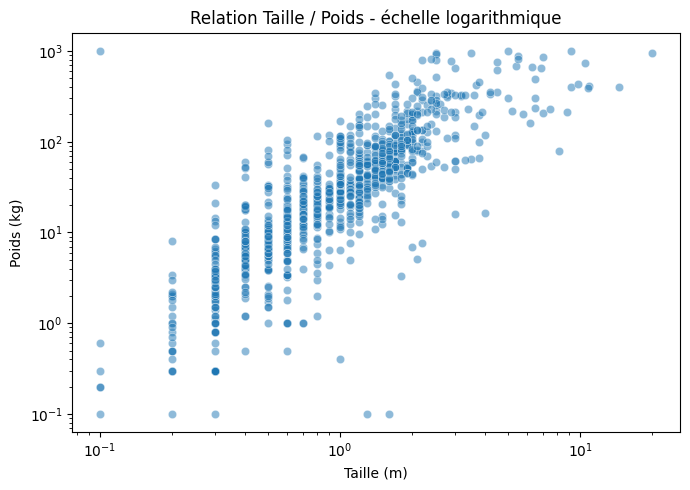

In [16]:
temp = df[["Taille_m", "Poids_kg"]].dropna()

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=temp,
    x="Taille_m",
    y="Poids_kg",
    alpha=0.5
)

plt.xscale("log")
plt.yscale("log")

plt.title("Relation Taille / Poids - échelle logarithmique")
plt.xlabel("Taille (m)")
plt.ylabel("Poids (kg)")

plt.tight_layout()
plt.show()

La représentation logarithmique met beaucoup mieux en évidence la relation entre la taille
et le poids.

Malgré quelques observations atypiques, le nuage suit une tendance croissante très nette,
cohérente avec le coefficient de Spearman élevé (`rho ≈ 0,85`).

L'utilisation d'échelles logarithmiques permet ici de limiter l'effet visuel des valeurs
extrêmes et de mieux représenter la structure générale de la relation.

## 4. Analyse des variables qualitatives

Les variables qualitatives sont étudiées afin de décrire la composition du jeu de données
et d'identifier d'éventuelles différences de profils entre les groupes.

Une attention particulière est portée aux types de Pokémon, aux générations et au statut
légendaire, qui pourront ensuite être mis en relation avec les variables quantitatives.

In [17]:
variables_quali = [
    "Generation",
    "Type1",
    "Type2",
    "PokemonDepart",
    "Base",
    "Evolution",
    "MegaEvolution",
    "Gigamax",
    "Legendaire"
]

for var in variables_quali:
    print(f"\n=== {var} ===")
    print(df[var].value_counts(dropna=False))


=== Generation ===
Generation
1    217
5    175
3    165
4    123
8    123
2    112
7     98
6     87
Name: count, dtype: int64

=== Type1 ===
Type1
Eau         140
Normal      121
Plante       97
Insecte      84
Psy          79
Feu          71
Électrik     64
Roche        58
Combat       50
Ténèbres     49
Sol          44
Poison       43
Spectre      43
Dragon       42
Acier        42
Glace        40
Fée          24
Vol           9
Name: count, dtype: int64

=== Type2 ===
Type2
Aucun       505
Vol         115
Poison       44
Psy          44
Fée          43
Sol          40
Dragon       39
Acier        36
Combat       33
Spectre      30
Plante       30
Ténèbres     28
Eau          22
Roche        20
Feu          19
Glace        19
Normal       12
Électrik     11
Insecte      10
Name: count, dtype: int64

=== PokemonDepart ===
PokemonDepart
False    1074
True       26
Name: count, dtype: int64

=== Base ===
Base
True     571
False    529
Name: count, dtype: int64

=== Evolution ===
Evol

In [18]:
for var in ["Generation", "Type1", "Type2", "Legendaire"]:
    
    effectifs = df[var].value_counts(dropna=False)
    pourcentages = df[var].value_counts(
        dropna=False,
        normalize=True
    ) * 100

    tableau = pd.DataFrame({
        "Effectif": effectifs,
        "Pourcentage": pourcentages.round(2)
    })

    print(f"\n=== {var} ===")
    display(tableau)


=== Generation ===


,Effectif,Pourcentage
Generation,,
1,217,19.73
5,175,15.91
3,165,15.00
4,123,11.18
8,123,11.18
2,112,10.18
7,98,8.91
6,87,7.91



=== Type1 ===


,Effectif,Pourcentage
Type1,,
Eau,140,12.73
Normal,121,11.00
Plante,97,8.82
Insecte,84,7.64
Psy,79,7.18
Feu,71,6.45
Électrik,64,5.82
Roche,58,5.27
Combat,50,4.55



=== Type2 ===


,Effectif,Pourcentage
Type2,,
Aucun,505,45.91
Vol,115,10.45
Poison,44,4.00
Psy,44,4.00
Fée,43,3.91
Sol,40,3.64
Dragon,39,3.55
Acier,36,3.27
Combat,33,3.00



=== Legendaire ===


,Effectif,Pourcentage
Legendaire,,
False,979,89.0
True,121,11.0


### Interprétation des variables qualitatives

La première génération est la plus représentée dans le jeu de données avec 217
observations (19,73 %), devant les générations 5 et 3.

Le type principal le plus fréquent est le type Eau (12,73 %), suivi des types
Normal (11,00 %) et Plante (8,82 %). À l'inverse, le type Vol apparaît rarement
comme type principal.

Concernant le second type, 505 observations (45,91 %) sont monotypes et ne possèdent
donc pas de `Type2`, tandis que 595 observations (54,09 %) possèdent deux types.

Le type Vol est particulièrement fréquent comme second type, ce qui montre que
les distributions de `Type1` et `Type2` ne doivent pas être interprétées comme
deux répartitions équivalentes.

Enfin, 121 observations (11 %) correspondent à des Pokémon légendaires, contre
979 observations non légendaires.

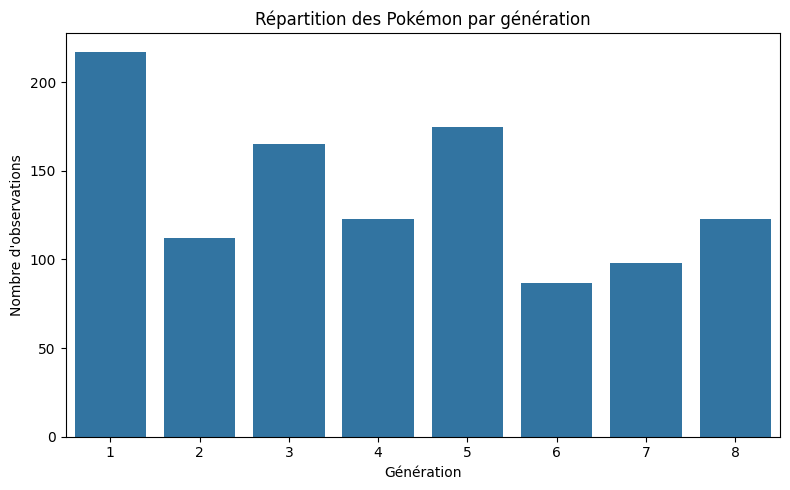

In [19]:
generation_counts = (
    df["Generation"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=generation_counts.index,
    y=generation_counts.values
)

plt.title("Répartition des Pokémon par génération")
plt.xlabel("Génération")
plt.ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()

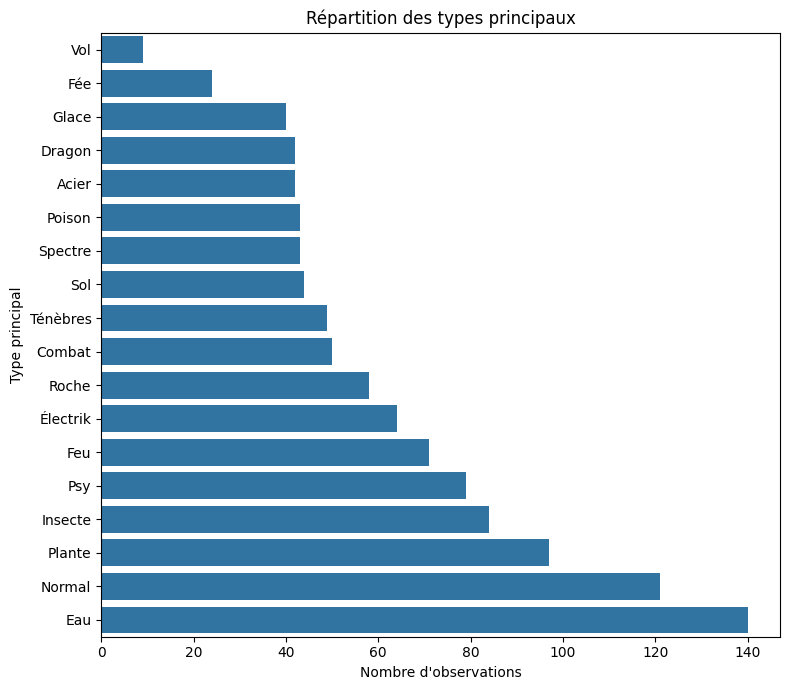

In [20]:
type1_counts = df["Type1"].value_counts().sort_values()

plt.figure(figsize=(8, 7))

sns.barplot(
    x=type1_counts.values,
    y=type1_counts.index
)

plt.title("Répartition des types principaux")
plt.xlabel("Nombre d'observations")
plt.ylabel("Type principal")

plt.tight_layout()
plt.show()

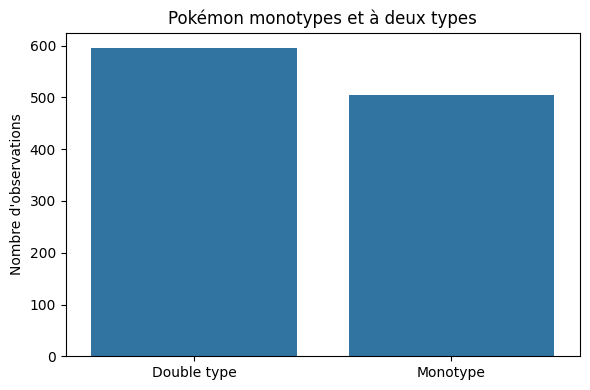

In [21]:
df["StructureType"] = np.where(
    df["Type2"] == "Aucun",
    "Monotype",
    "Double type"
)

structure_counts = df["StructureType"].value_counts()

plt.figure(figsize=(6, 4))

sns.barplot(
    x=structure_counts.index,
    y=structure_counts.values
)

plt.title("Pokémon monotypes et à deux types")
plt.xlabel("")
plt.ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()

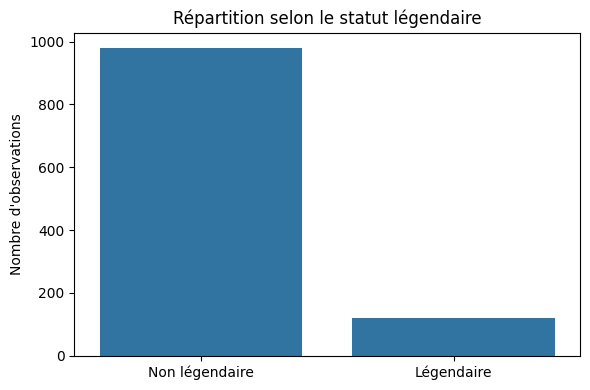

In [22]:
legendaire_counts = (
    df["Legendaire"]
    .map({
        False: "Non légendaire",
        True: "Légendaire"
    })
    .value_counts()
)

plt.figure(figsize=(6, 4))

sns.barplot(
    x=legendaire_counts.index,
    y=legendaire_counts.values
)

plt.title("Répartition selon le statut légendaire")
plt.xlabel("")
plt.ylabel("Nombre d'observations")

plt.tight_layout()
plt.show()

### Interprétation des répartitions qualitatives

La génération 1 est la plus représentée dans le jeu de données, tandis que la génération 6
est la moins représentée. La composition du jeu de données n'est donc pas homogène selon
les générations.

Concernant le type principal, le type Eau est le plus fréquent, suivi des types Normal
et Plante. À l'inverse, le type Vol apparaît rarement comme type principal.

Les Pokémon à deux types représentent une légère majorité des observations
(54,09 %) par rapport aux Pokémon monotypes (45,91 %).

Enfin, les Pokémon légendaires représentent seulement 11 % du jeu de données, ce qui
crée un fort déséquilibre entre les deux groupes.

## 5. Comparaison des Pokémon légendaires et non légendaires

On cherche à déterminer si les Pokémon légendaires présentent des statistiques globales
plus élevées que les Pokémon non légendaires.

Le seuil de significativité est fixé à 5 %.

Compte tenu de la présence de valeurs extrêmes et du déséquilibre des effectifs entre
les deux groupes, un test non paramétrique de Mann-Whitney est utilisé.

In [23]:
leg = df[df["Legendaire"]]["Total"]
non_leg = df[~df["Legendaire"]]["Total"]

print("Légendaires")
print("n :", len(leg))
print("moyenne :", leg.mean())
print("médiane :", leg.median())

print()

print("Non légendaires")
print("n :", len(non_leg))
print("moyenne :", non_leg.mean())
print("médiane :", non_leg.median())

Légendaires
n : 121
moyenne : 618.8595041322315
médiane : 600.0

Non légendaires
n : 979
moyenne : 420.7711950970378
médiane : 440.0


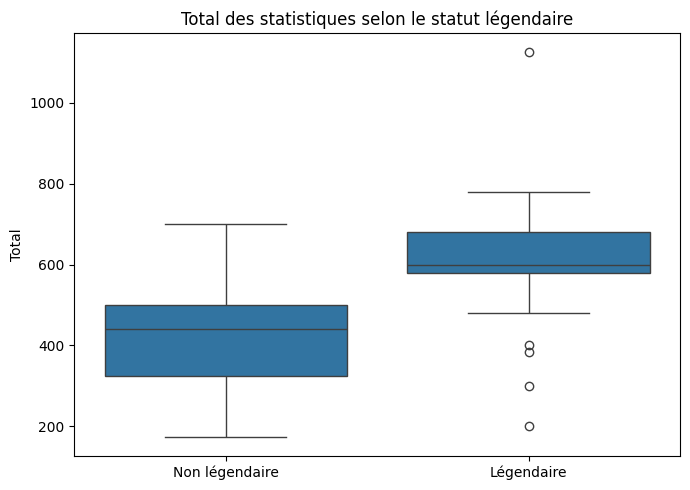

In [24]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="Legendaire",
    y="Total"
)

plt.xticks(
    [0, 1],
    ["Non légendaire", "Légendaire"]
)

plt.title("Total des statistiques selon le statut légendaire")
plt.xlabel("")
plt.ylabel("Total")

plt.tight_layout()
plt.show()

In [25]:
u_stat, p_value = stats.mannwhitneyu(
    leg,
    non_leg,
    alternative="two-sided"
)

n1 = len(leg)
n2 = len(non_leg)

rank_biserial = 2 * u_stat / (n1 * n2) - 1

print("Statistique U :", u_stat)
print("p-value :", p_value)
print("Effet rank-bisérial :", rank_biserial)

Statistique U : 111507.5
p-value : 1.209283512029611e-56
Effet rank-bisérial : 0.8826344980119705


### Interprétation

Les Pokémon légendaires présentent des statistiques globales nettement supérieures
aux Pokémon non légendaires.

Leur médiane de `Total` est de 600 contre 440 pour les non légendaires, et leur moyenne
est également beaucoup plus élevée (618,9 contre 420,8).

Le test de Mann-Whitney confirme que cette différence est statistiquement significative
(`p < 0,001`).

La taille d'effet rank-bisériale est de `0,883`, ce qui indique une différence de très
forte intensité entre les deux groupes.

Le boxplot montre cependant une valeur extrêmement élevée pour Éthernatos Infinimax.
Un test de robustesse est donc réalisé sans cette observation afin de vérifier que
le résultat ne dépend pas uniquement de cet outlier.

In [26]:
df_robuste = df[df["Nom"] != "Éthernatos Infinimax"]

leg_robuste = df_robuste[df_robuste["Legendaire"]]["Total"]
non_leg_robuste = df_robuste[~df_robuste["Legendaire"]]["Total"]

u_stat_robuste, p_value_robuste = stats.mannwhitneyu(
    leg_robuste,
    non_leg_robuste,
    alternative="two-sided"
)

n1 = len(leg_robuste)
n2 = len(non_leg_robuste)

rank_biserial_robuste = (
    2 * u_stat_robuste / (n1 * n2) - 1
)

print("Légendaires sans Éthernatos Infinimax")
print("n :", len(leg_robuste))
print("moyenne :", leg_robuste.mean())
print("médiane :", leg_robuste.median())

print()
print("p-value :", p_value_robuste)
print("Effet rank-bisérial :", rank_biserial_robuste)

Légendaires sans Éthernatos Infinimax
n : 120
moyenne : 614.6416666666667
médiane : 600.0

p-value : 4.043833585969802e-56
Effet rank-bisérial : 0.8816564521620702


### Test de robustesse

Après exclusion d'Éthernatos Infinimax, la médiane du `Total` des Pokémon légendaires
reste égale à 600 et le test de Mann-Whitney reste hautement significatif
(`p < 0,001`).

La taille d'effet rank-bisériale reste pratiquement inchangée (`0,882`).

La différence observée entre Pokémon légendaires et non légendaires ne dépend donc pas
de cette observation extrême.

## 6. Influence du type principal sur le Total

On cherche à déterminer si la distribution du `Total` des statistiques diffère selon
le type principal du Pokémon.

Comme les distributions ne sont pas supposées normales et que les effectifs diffèrent
entre les types, le test non paramétrique de Kruskal-Wallis est utilisé.

Le seuil de significativité est fixé à 5 %.

In [27]:
resume_type1 = (
    df.groupby("Type1")["Total"]
    .agg(
        effectif="count",
        moyenne="mean",
        mediane="median"
    )
    .sort_values("mediane", ascending=False)
)

resume_type1

,effectif,moyenne,mediane
Type1,,,
Dragon,42,540.261905,600.0
Acier,42,491.904762,500.0
Vol,9,446.111111,495.0
Psy,79,490.227848,490.0
Roche,58,451.931034,487.0
Feu,71,459.352113,484.0
Électrik,64,448.328125,483.0
Combat,50,455.280000,476.0
Spectre,43,445.372093,476.0


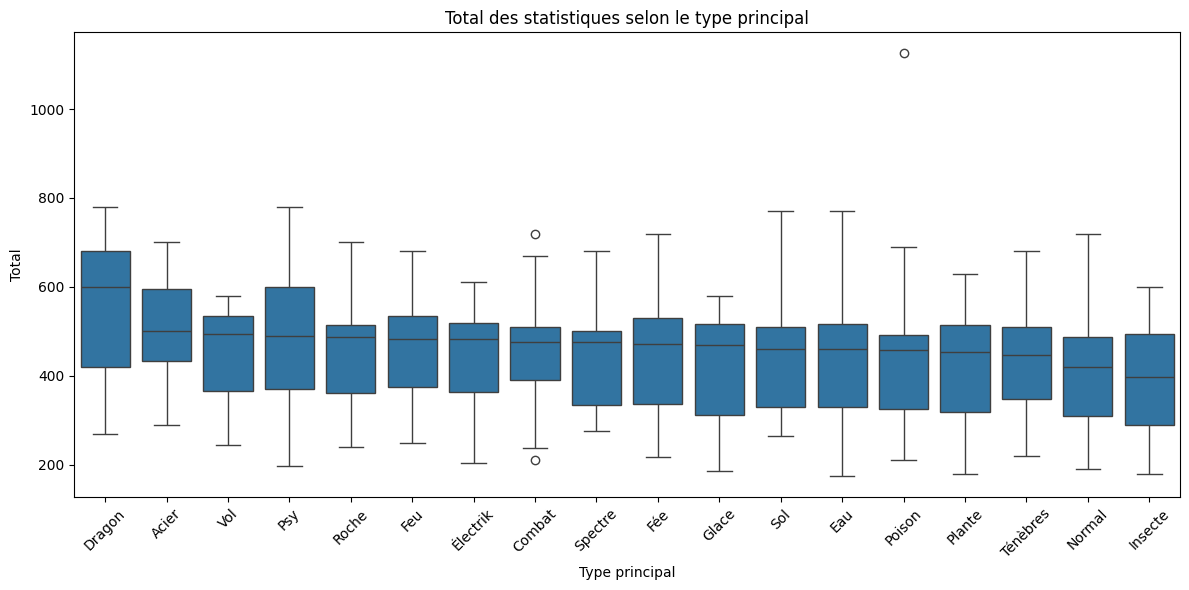

In [28]:
ordre_types = resume_type1.index

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Type1",
    y="Total",
    order=ordre_types
)

plt.xticks(rotation=45)
plt.title("Total des statistiques selon le type principal")
plt.xlabel("Type principal")
plt.ylabel("Total")

plt.tight_layout()
plt.show()

In [29]:
groupes_type1 = [
    groupe["Total"].values
    for _, groupe in df.groupby("Type1")
]

h_stat, p_value = stats.kruskal(*groupes_type1)

print("Statistique H :", h_stat)
print("p-value :", p_value)

Statistique H : 71.93147462212733
p-value : 1.000290992831299e-08


### Interprétation

Le test de Kruskal-Wallis met en évidence une différence statistiquement significative
du `Total` selon le type principal du Pokémon (`H = 71,93`, `p < 0,001`).

Le type Dragon présente la médiane la plus élevée (`600`), tandis que les types
Insecte (`397,5`) et Normal (`420`) présentent les médianes les plus faibles.

Cependant, ce test global indique seulement qu'au moins un groupe diffère des autres.
Il ne permet pas d'identifier directement les types responsables de cette différence.

De plus, certaines catégories sont peu représentées, comme le type Vol, et certains
types peuvent contenir davantage de Pokémon légendaires que d'autres. Ces éléments
doivent être pris en compte avant d'attribuer les différences observées uniquement
au type principal.

In [30]:
legendaire_par_type = (
    df.groupby("Type1")["Legendaire"]
    .agg(
        effectif="count",
        nb_legendaires="sum",
        proportion_legendaires="mean"
    )
)

legendaire_par_type["proportion_legendaires"] *= 100

legendaire_par_type.sort_values(
    "proportion_legendaires",
    ascending=False
)

,effectif,nb_legendaires,proportion_legendaires
Type1,,,
Psy,79,30,37.974684
Dragon,42,15,35.714286
Vol,9,2,22.222222
Acier,42,9,21.428571
Combat,50,9,18.000000
Fée,24,4,16.666667
Électrik,64,7,10.937500
Sol,44,4,9.090909
Ténèbres,49,4,8.163265


In [31]:
df_non_leg = df[~df["Legendaire"]]

groupes_type1_non_leg = [
    groupe["Total"].values
    for _, groupe in df_non_leg.groupby("Type1")
]

h_non_leg, p_non_leg = stats.kruskal(
    *groupes_type1_non_leg
)

print("H sans légendaires :", h_non_leg)
print("p-value sans légendaires :", p_non_leg)

H sans légendaires : 35.22243494863775
p-value sans légendaires : 0.005815818349686736


### Influence du statut légendaire

La proportion de Pokémon légendaires varie fortement selon le type principal.

Les types Psy et Dragon présentent notamment des proportions très élevées de Pokémon
légendaires, respectivement 37,97 % et 35,71 %, alors que le type Insecte n'en contient
que 1,19 %.

Cette différence de composition peut expliquer une partie des écarts de `Total`
observés entre les types.

Après exclusion des Pokémon légendaires, le test de Kruskal-Wallis reste significatif
(`H = 35,22`, `p = 0,0058`), ce qui indique que des différences entre types subsistent.

Cependant, la taille d'effet diminue nettement :
- jeu de données complet : epsilon² ≈ 0,051 ;
- sans Pokémon légendaires : epsilon² ≈ 0,019.

Le statut légendaire explique donc une partie importante des différences observées entre
les types, même si un effet résiduel du type principal demeure.

In [32]:
epsilon_global = (
    (71.93147462212733 - df["Type1"].nunique() + 1)
    / (len(df) - df["Type1"].nunique())
)

epsilon_non_leg = (
    (h_non_leg - df_non_leg["Type1"].nunique() + 1)
    / (len(df_non_leg) - df_non_leg["Type1"].nunique())
)

print("Epsilon² global :", epsilon_global)
print("Epsilon² sans légendaires :", epsilon_non_leg)

Epsilon² global : 0.050768460833759084
Epsilon² sans légendaires : 0.01896195103916519


### 6.1 Comparaisons post-hoc entre types

Le test global de Kruskal-Wallis indique qu'au moins un type principal diffère des autres,
mais il ne précise pas quelles paires sont concernées.

Des comparaisons deux à deux sont donc réalisées avec le test de Mann-Whitney.
Les p-values sont corrigées selon la méthode de Holm afin de tenir compte du nombre
important de comparaisons effectuées.

In [34]:
from itertools import combinations

types = sorted(df["Type1"].unique())

resultats_posthoc = []

for type1, type2 in combinations(types, 2):

    groupe1 = df[df["Type1"] == type1]["Total"]
    groupe2 = df[df["Type1"] == type2]["Total"]

    u_stat, p_value = stats.mannwhitneyu(
        groupe1,
        groupe2,
        alternative="two-sided"
    )

    resultats_posthoc.append({
        "Type 1": type1,
        "Type 2": type2,
        "n1": len(groupe1),
        "n2": len(groupe2),
        "mediane_1": groupe1.median(),
        "mediane_2": groupe2.median(),
        "p_value": p_value
    })

posthoc = pd.DataFrame(resultats_posthoc)

In [35]:
# Correction de Holm des p-values

m = len(posthoc)

ordre = np.argsort(posthoc["p_value"].values)
p_triees = posthoc["p_value"].values[ordre]

p_corrigees_triees = np.zeros(m)

max_precedent = 0

for i, p in enumerate(p_triees):

    p_corrigee = (m - i) * p

    max_precedent = max(
        max_precedent,
        p_corrigee
    )

    p_corrigees_triees[i] = min(
        max_precedent,
        1
    )

p_corrigees = np.zeros(m)
p_corrigees[ordre] = p_corrigees_triees

posthoc["p_corrigee"] = p_corrigees
posthoc["significatif"] = posthoc["p_corrigee"] < 0.05

In [36]:
posthoc_significatif = (
    posthoc[posthoc["significatif"]]
    .sort_values("p_corrigee")
)

print(
    "Nombre de comparaisons significatives après correction :",
    len(posthoc_significatif)
)

posthoc_significatif[
    [
        "Type 1",
        "Type 2",
        "mediane_1",
        "mediane_2",
        "p_corrigee"
    ]
].head(30)

Nombre de comparaisons significatives après correction : 9


,Type 1,Type 2,mediane_1,mediane_2,p_corrigee
37,Dragon,Insecte,600.0,397.5,0.000068
38,Dragon,Normal,600.0,420.0,0.000111
101,Insecte,Psy,397.5,490.0,0.001090
39,Dragon,Plante,600.0,454.0,0.001792
110,Normal,Psy,420.0,490.0,0.002237
6,Acier,Insecte,500.0,397.5,0.002956
7,Acier,Normal,500.0,420.0,0.006783
33,Dragon,Eau,600.0,460.0,0.008848
64,Feu,Insecte,484.0,397.5,0.024010


### Résultats des comparaisons post-hoc

Après correction de Holm, neuf comparaisons entre types restent statistiquement
significatives.

Les différences les plus marquées concernent notamment :

- Dragon vs Insecte : médianes 600 contre 397,5 ;
- Dragon vs Normal : 600 contre 420 ;
- Dragon vs Plante : 600 contre 454 ;
- Dragon vs Eau : 600 contre 460 ;
- Acier vs Insecte : 500 contre 397,5 ;
- Acier vs Normal : 500 contre 420 ;
- Psy vs Insecte : 490 contre 397,5 ;
- Psy vs Normal : 490 contre 420 ;
- Feu vs Insecte : 484 contre 397,5.

Ces résultats confirment que l'effet global du type principal n'est pas réparti
uniformément entre toutes les catégories : quelques contrastes concentrent
l'essentiel des différences observées.

In [41]:
types_non_leg = sorted(df_non_leg["Type1"].unique())

resultats_posthoc_non_leg = []

for type1, type2 in combinations(types_non_leg, 2):

    groupe1 = df_non_leg[df_non_leg["Type1"] == type1]["Total"]
    groupe2 = df_non_leg[df_non_leg["Type1"] == type2]["Total"]

    u_stat, p_value = stats.mannwhitneyu(
        groupe1,
        groupe2,
        alternative="two-sided"
    )

    resultats_posthoc_non_leg.append({
        "Type 1": type1,
        "Type 2": type2,
        "mediane_1": groupe1.median(),
        "mediane_2": groupe2.median(),
        "p_value": p_value
    })

posthoc_non_leg = pd.DataFrame(resultats_posthoc_non_leg)

In [42]:
m = len(posthoc_non_leg)

ordre = np.argsort(posthoc_non_leg["p_value"].values)
p_triees = posthoc_non_leg["p_value"].values[ordre]

p_corrigees_triees = np.zeros(m)

max_precedent = 0

for i, p in enumerate(p_triees):

    p_corrigee = (m - i) * p

    max_precedent = max(
        max_precedent,
        p_corrigee
    )

    p_corrigees_triees[i] = min(
        max_precedent,
        1
    )

p_corrigees = np.zeros(m)
p_corrigees[ordre] = p_corrigees_triees

posthoc_non_leg["p_corrigee"] = p_corrigees
posthoc_non_leg["significatif"] = (
    posthoc_non_leg["p_corrigee"] < 0.05
)

In [43]:
posthoc_non_leg_significatif = (
    posthoc_non_leg[
        posthoc_non_leg["significatif"]
    ]
    .sort_values("p_corrigee")
)

print(
    "Comparaisons significatives sans légendaires :",
    len(posthoc_non_leg_significatif)
)

posthoc_non_leg_significatif[
    [
        "Type 1",
        "Type 2",
        "mediane_1",
        "mediane_2",
        "p_corrigee"
    ]
]

Comparaisons significatives sans légendaires : 0


,Type 1,Type 2,mediane_1,mediane_2,p_corrigee


### Vérification sans Pokémon légendaires

Lorsque les Pokémon légendaires sont exclus, le test global de Kruskal-Wallis reste
significatif (`p = 0,0058`), mais sa taille d'effet devient faible
(`epsilon² ≈ 0,019`).

Après correction de Holm, aucune comparaison deux à deux entre types n'est
statistiquement significative.

Ainsi, il subsiste un faible signal global entre les types chez les Pokémon
non légendaires, mais aucune paire particulière ne présente une différence suffisamment
forte pour résister à la correction des comparaisons multiples.

Les différences observées dans le jeu de données complet semblent donc largement
amplifiées par la concentration inégale de Pokémon légendaires dans certains types,
notamment Psy et Dragon.

## 7. Évolution du Total selon les générations

On cherche à déterminer si la puissance globale des Pokémon, mesurée par la variable
`Total`, diffère selon les générations.

La génération est considérée ici comme une variable qualitative ordonnée et non comme
une variable quantitative continue.

Comme les distributions de `Total` ne sont pas supposées normales, les huit générations
sont comparées à l'aide du test non paramétrique de Kruskal-Wallis.

Le seuil de significativité est fixé à 5 %.

In [44]:
resume_generation = (
    df.groupby("Generation")["Total"]
    .agg(
        effectif="count",
        moyenne="mean",
        mediane="median",
        ecart_type="std"
    )
)

resume_generation

,effectif,moyenne,mediane,ecart_type
Generation,,,,
1,217,430.147465,440.0,112.454626
2,112,419.214286,430.0,119.260365
3,165,435.993939,440.0,135.063964
4,123,462.609756,490.0,121.848174
5,175,435.451429,470.0,106.714662
6,87,444.574713,470.0,118.547276
7,98,463.000000,482.5,123.492393
8,123,466.886179,495.0,130.591103


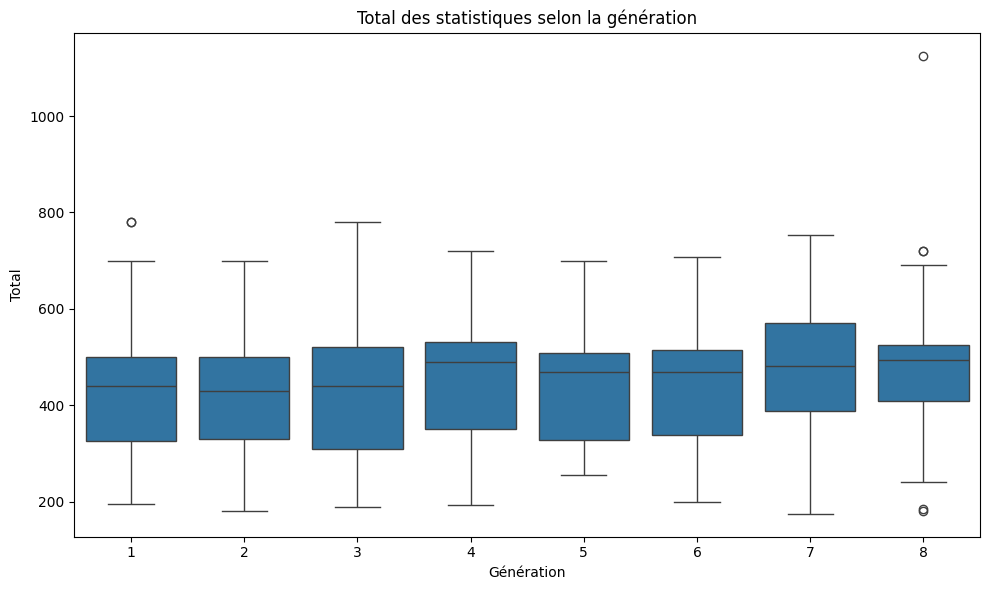

In [45]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Generation",
    y="Total"
)

plt.title("Total des statistiques selon la génération")
plt.xlabel("Génération")
plt.ylabel("Total")

plt.tight_layout()
plt.show()

In [46]:
groupes_generation = [
    groupe["Total"].values
    for _, groupe in df.groupby("Generation")
]

h_generation, p_generation = stats.kruskal(
    *groupes_generation
)

print("Statistique H :", h_generation)
print("p-value :", p_generation)

Statistique H : 22.415432525728058
p-value : 0.0021534348343768715


In [47]:
n = len(df)
k = df["Generation"].nunique()

epsilon_generation = (
    (h_generation - k + 1)
    / (n - k)
)

print("Epsilon² :", epsilon_generation)

Epsilon² : 0.01411669645213192


### Interprétation

Le test de Kruskal-Wallis met en évidence une différence statistiquement significative
du `Total` selon les générations (`H = 22,42`, `p = 0,0022`).

Cependant, la taille d'effet est très faible (`epsilon² ≈ 0,014`), ce qui signifie que
la génération explique seulement une faible part des différences de puissance globale
observées.

Les générations 7 et 8 présentent des médianes relativement élevées, respectivement
482,5 et 495, tandis que les générations 1 à 3 ont des médianes plus faibles.

Cette évolution n'est toutefois pas strictement croissante : la génération 4 présente
par exemple une médiane de 490, supérieure à celles des générations 5 et 6.

On ne peut donc pas conclure à ce stade à un phénomène simple et monotone de
"power creep".

In [48]:
rho_generation, p_spearman_generation = stats.spearmanr(
    df["Generation"],
    df["Total"]
)

print("rho de Spearman :", rho_generation)
print("p-value :", p_spearman_generation)

rho de Spearman : 0.10709718472912923
p-value : 0.00037338873622788936


In [49]:
generation_leg = (
    df.groupby("Generation")["Legendaire"]
    .agg(
        effectif="count",
        nb_legendaires="sum",
        proportion_legendaires="mean"
    )
)

generation_leg["proportion_legendaires"] *= 100

generation_leg

,effectif,nb_legendaires,proportion_legendaires
Generation,,,
1,217,10,4.608295
2,112,6,5.357143
3,165,18,10.909091
4,123,18,14.634146
5,175,19,10.857143
6,87,10,11.494253
7,98,20,20.408163
8,123,20,16.260163


In [50]:
df_non_leg_generation = df[~df["Legendaire"]]

rho_non_leg, p_non_leg_generation = stats.spearmanr(
    df_non_leg_generation["Generation"],
    df_non_leg_generation["Total"]
)

print("rho sans légendaires :", rho_non_leg)
print("p-value sans légendaires :", p_non_leg_generation)

rho sans légendaires : 0.06884960695707558
p-value sans légendaires : 0.031237196423693818


### Tendance du Total au fil des générations

La corrélation de Spearman entre la génération et le `Total` est positive et
statistiquement significative (`rho = 0,107`, `p < 0,001`).

Cependant, la valeur de `rho` est faible, ce qui indique que la relation entre
la génération et la puissance globale est peu marquée.

La proportion de Pokémon légendaires augmente également dans les générations récentes :
elle passe par exemple de 4,61 % en génération 1 à 20,41 % en génération 7.

Après exclusion des Pokémon légendaires, la corrélation reste significative
(`rho = 0,069`, `p = 0,031`), mais devient encore plus faible.

Ces résultats ne permettent donc pas de conclure à un fort phénomène de "power creep".
On observe seulement une légère tendance à l'augmentation du `Total` au fil des
générations, en partie expliquée par une proportion plus importante de Pokémon
légendaires dans les générations récentes.

## 8. Même puissance globale, profils statistiques différents

La variable `Total` résume la somme des six statistiques de combat, mais elle ne permet
pas de distinguer la manière dont cette puissance est répartie entre PV, Attaque,
Défense, Attaque Spéciale, Défense Spéciale et Vitesse.

On cherche donc à identifier des Pokémon ayant un même `Total`, mais des profils de
combat très différents.

Cette analyse permet de montrer l'intérêt d'une approche multivariée telle que l'ACP.

In [51]:
stats_combat = [
    "PV",
    "Attaque",
    "Defense",
    "AttaqueSpeciale",
    "DefenseSpeciale",
    "Vitesse"
]

stats_standardisees = (
    df[stats_combat] - df[stats_combat].mean()
) / df[stats_combat].std()

In [52]:
from itertools import combinations

paires = []

for total, groupe in df.groupby("Total"):

    if len(groupe) < 2:
        continue

    indices = groupe.index

    for i, j in combinations(indices, 2):

        distance = np.sqrt(
            (
                (stats_standardisees.loc[i] - stats_standardisees.loc[j]) ** 2
            ).sum()
        )

        paires.append({
            "Pokemon 1": df.loc[i, "Nom"],
            "Pokemon 2": df.loc[j, "Nom"],
            "Total": total,
            "Distance": distance
        })

paires_profils = (
    pd.DataFrame(paires)
    .sort_values("Distance", ascending=False)
)

paires_profils.head(10)

,Pokemon 1,Pokemon 2,Total,Distance
4297,Caratroc,Corboss,505.0,10.396604
4298,Caratroc,Bétochef,505.0,9.142927
4241,Nidoking,Caratroc,505.0,8.974610
4299,Caratroc,Polagriffe,505.0,8.901849
4302,Caratroc,Galvagon,505.0,8.809910
5340,Leuphorie,Tranchodon,540.0,8.753604
4277,Mackogneur,Caratroc,505.0,8.736444
4287,Mackogneur Gigamax,Caratroc,505.0,8.736444
4303,Caratroc,Galvagla,505.0,8.507237
6503,Deoxys - Forme Attaque,Deoxys - Forme Défense,600.0,8.492731


In [53]:
paire_extreme = paires_profils.iloc[0]

nom1 = paire_extreme["Pokemon 1"]
nom2 = paire_extreme["Pokemon 2"]

comparaison = (
    df[df["Nom"].isin([nom1, nom2])]
    [["Nom", "Total"] + stats_combat]
    .set_index("Nom")
)

comparaison

,Total,PV,Attaque,Defense,AttaqueSpeciale,DefenseSpeciale,Vitesse
Nom,,,,,,,
Caratroc,505.0,20.0,10.0,230.0,10.0,230.0,5.0
Corboss,505.0,100.0,125.0,52.0,105.0,52.0,71.0


## 8. Même puissance globale, profils statistiques différents

La variable `Total` résume la somme des six statistiques de combat, mais elle ne décrit
pas la manière dont cette puissance est répartie entre les différentes composantes
(PV, Attaque, Défense, Attaque Spéciale, Défense Spéciale et Vitesse).

Pour illustrer cette limite, nous avons recherché, parmi les Pokémon ayant un même
`Total`, les paires présentant les profils statistiques les plus éloignés. La distance
a été calculée à partir des statistiques de combat standardisées.

La paire la plus contrastée est constituée de **Caratroc** et **Corboss**, qui ont
tous deux un `Total` de **505**, mais des répartitions de statistiques très différentes.

Caratroc présente un profil extrêmement défensif, avec des valeurs très élevées en
Défense et Défense Spéciale (230), mais des statistiques offensives, de vitesse et de PV
très faibles. À l'inverse, Corboss présente un profil beaucoup plus offensif et plus
équilibré, avec des PV, une Attaque et une Attaque Spéciale élevées, mais des défenses
modestes.

Ce résultat montre que deux Pokémon de puissance globale comparable peuvent avoir des
profils de combat radicalement différents. Il justifie donc l’intérêt d’une approche
multivariée comme l’ACP, qui permet d’étudier la structure interne des statistiques,
et pas seulement leur somme.

In [54]:
comparaison.T

Nom,Caratroc,Corboss
Total,505.0,505.0
PV,20.0,100.0
Attaque,10.0,125.0
Defense,230.0,52.0
AttaqueSpeciale,10.0,105.0
DefenseSpeciale,230.0,52.0
Vitesse,5.0,71.0


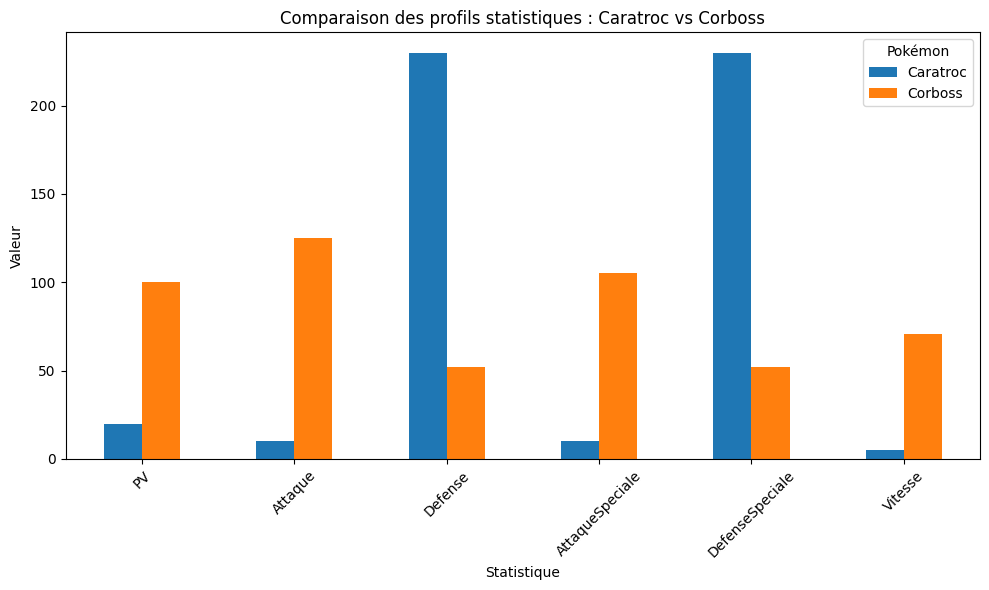

In [55]:
stats_combat = [
    "PV",
    "Attaque",
    "Defense",
    "AttaqueSpeciale",
    "DefenseSpeciale",
    "Vitesse"
]

comparaison_plot = comparaison[stats_combat].T

ax = comparaison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparaison des profils statistiques : Caratroc vs Corboss")
plt.xlabel("Statistique")
plt.ylabel("Valeur")
plt.xticks(rotation=45)
plt.legend(title="Pokémon")
plt.tight_layout()
plt.show()

Le graphique confirme visuellement l’opposition entre les deux profils. Caratroc concentre
presque toute sa puissance dans les dimensions défensives, tandis que Corboss présente
des statistiques plus élevées en PV, Attaque, Attaque Spéciale et Vitesse. Ainsi, un même
`Total` peut correspondre à des styles de combat très différents.

## Conclusion de l'analyse exploratoire

L'analyse exploratoire met en évidence plusieurs structures dans les données.

La puissance globale des Pokémon varie fortement selon certaines caractéristiques,
notamment le statut légendaire. Le type principal et la génération sont également
associés au `Total`, mais leurs effets sont plus faibles et doivent être interprétés
avec prudence en raison d'effets de composition.

Les analyses de corrélation montrent par ailleurs que plusieurs statistiques de combat
évoluent conjointement, tandis que certaines dimensions restent relativement
indépendantes.

Enfin, l'exemple de Pokémon possédant un même `Total` mais des profils statistiques
radicalement différents montre qu'une simple somme des statistiques ne permet pas
de décrire correctement leur structure.

Une approche multivariée est donc nécessaire pour étudier simultanément les six
statistiques de combat et identifier les principales dimensions qui différencient
les profils de Pokémon. Nous poursuivons cette analyse à l'aide d'une Analyse en
Composantes Principales (ACP).